# Comparing the Three-Body Model to Artemis II, with JPL Data

`ApolloComparison.ipynb` checks the model against Apollo 8. Apollo 8 is an awkward comparison for this project, because it left its free return on purpose: it retargeted the lunar pass and then entered lunar orbit for 20 hours. **Artemis II** (April 2026) is a much closer match to what `main.tex` studies:

| | Our model (`main.tex`) | Apollo 8 (1968) | Artemis II (2026) |
|---|---|---|---|
| Trajectory | Free return | Free return until LOI, then lunar orbit | **Free return the whole way** |
| Burns after TLI | None | 20 ft/s retarget, LOI (2,997 ft/s), TEI (3,519 ft/s) | **Trims only: 0.5–3 m/s** |
| Lunar pass | Behind the Moon | 60 n mi lunar orbit | **6,545 km altitude, behind the Moon** |
| Entry | Corridor $-7.4^\circ \le \gamma_{EI} \le -5.25^\circ$ | $-6.5^\circ$ | **Measured below** |
| Data | — | Published tables | **Full flown trajectory every 5 min (JPL Horizons)** |

This notebook uses two JPL datasets:

1. **JPL Three-Body Periodic Orbits catalog**, to verify the model code. JPL computed these orbits independently in the same CR3BP. If `f_spacecraft` and `rk4` are right, every catalogued orbit should close on itself after one period, with its Jacobi constant unchanged. This is the Jacobi-constant and convergence verification planned in `main.tex` (Table 3), run against an outside reference.
2. **JPL Horizons ephemeris of Artemis II** (spacecraft −1024, from NASA/JSC navigation data) and of the Moon, to compare the model with a real free return.

**Sources**

- JPL Solar System Dynamics, *Three-Body Periodic Orbits API*, https://ssd-api.jpl.nasa.gov/doc/periodic_orbits.html
- JPL Solar System Dynamics, *Horizons API*, https://ssd-api.jpl.nasa.gov/doc/horizons.html. Artemis II (−1024) flown trajectory and mission event list; Moon (301).

Both downloads are cached under `data/` by `freereturn/jpl.py`, so this notebook runs offline and always uses the same numbers.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from freereturn.constants import *
from freereturn.dynamics import f_spacecraft, jacobi_constant
from freereturn.integrators import rk4
from freereturn.trajectory import (earth_dist, moon_dist, unit_scales, inertial_speed_fpa,
                                   rotating_frame, state_from_inertial, trajectory_events)
from freereturn.jpl import horizons_vectors, periodic_orbits
from freereturn.artemis2 import (HORIZONS_ID, HORIZONS_START, HORIZONS_STOP, HORIZONS_STEP,
                                 T_DATA_START, artemis2, artemis2_burns)
from freereturn.comparison import grade, plot_scorecard

MODEL_COLOUR = '#2a78d6'
MODEL_L_COLOUR = '#1baf7a'
REAL_COLOUR = '#eb6834'
INK = '#52514e'

## Part 1: Verifying the model against the JPL Three-Body Periodic Orbits catalog

Three planar Earth–Moon orbits from the catalog:

- a **distant retrograde orbit (DRO)** 70,000 km from the Moon's centre, the size of the orbit Artemis I flew (NASA NTRS 20230010480). It is stable, with stability index ≈ 1.
- an **L1 Lyapunov orbit** and an **L2 Lyapunov orbit**. These are strongly unstable (stability index 500–700), so any error in the equations of motion grows quickly. That makes them a harsh test.

The catalog uses its own mass ratio $\mu = 0.0121505856$ and units, so for this test `f_spacecraft` is called with the catalog's $\mu$. For each orbit we check that:

1. our `jacobi_constant` reproduces the catalog's Jacobi constant from the catalog's initial state,
2. after one catalogued period, `rk4` returns to the initial state, and
3. that closure error shrinks as $\Delta t^4$.

In [2]:
catalog_picks = [
    ('DRO, 70,000 km (Artemis I size)', 'dro', {'periodmin': 3.1554, 'periodmax': 3.1556}),
    ('L1 Lyapunov', 'lyapunov', {'libr': 1, 'periodmin': 2.9999, 'periodmax': 3.0}),
    ('L2 Lyapunov', 'lyapunov', {'libr': 2, 'periodmin': 3.4498, 'periodmax': 3.4499}),
]

catalog = []
for name, family, filters in catalog_picks:
    system, orbits = periodic_orbits(family, **filters)
    orbit = orbits[0]
    catalog.append({'name': name, 'mu': system['mu'], 'lunit': system['lunit'], 'tunit': system['tunit'],
                    'u0': orbit[[0, 1, 3, 4]], 'jacobi': orbit[6], 'period': orbit[7], 'stability': orbit[8]})

n_steps = 2**12

print(f'{"Orbit":<34}{"Period":>9}{"Stability":>11}{"C (catalog)":>20}{"C (ours)":>20}{"Closure error":>16}{"max |C - C0|":>14}')
print(f'{"":<34}{"(days)":>9}{"":>11}{"":>20}{"":>20}{"(km)":>16}{"":>14}')
print('-'*124)
for orb in catalog:
    f = lambda u, t, mu=orb['mu']: f_spacecraft(u, t, mu)
    u, times = rk4(f, orb['u0'], orb['period'], orb['period']/n_steps)
    C = jacobi_constant(u, orb['mu'])

    orb['u'] = u
    orb['closure_km'] = np.linalg.norm(u[-1, :2] - u[0, :2]) * orb['lunit']

    print(f'{orb["name"]:<34}{orb["period"]*orb["tunit"]/86400:>9.3f}{orb["stability"]:>11.1f}'
          f'{orb["jacobi"]:>20.14f}{jacobi_constant(orb["u0"], orb["mu"]):>20.14f}'
          f'{orb["closure_km"]:>16.2e}{np.abs(C - C[0]).max():>14.1e}')

Orbit                                Period  Stability         C (catalog)            C (ours)   Closure error  max |C - C0|
                                     (days)                                                               (km)              
----------------------------------------------------------------------------------------------------------------------------
DRO, 70,000 km (Artemis I size)      13.987        1.0    2.93007915586781    2.93007915586781        1.19e-06       2.8e-14


L1 Lyapunov                          13.298      690.1    3.11971078806608    3.11971078806608        1.38e-06       2.0e-14
L2 Lyapunov                          15.292      533.2    3.13858842142120    3.13858842142120        5.69e-07       1.0e-14


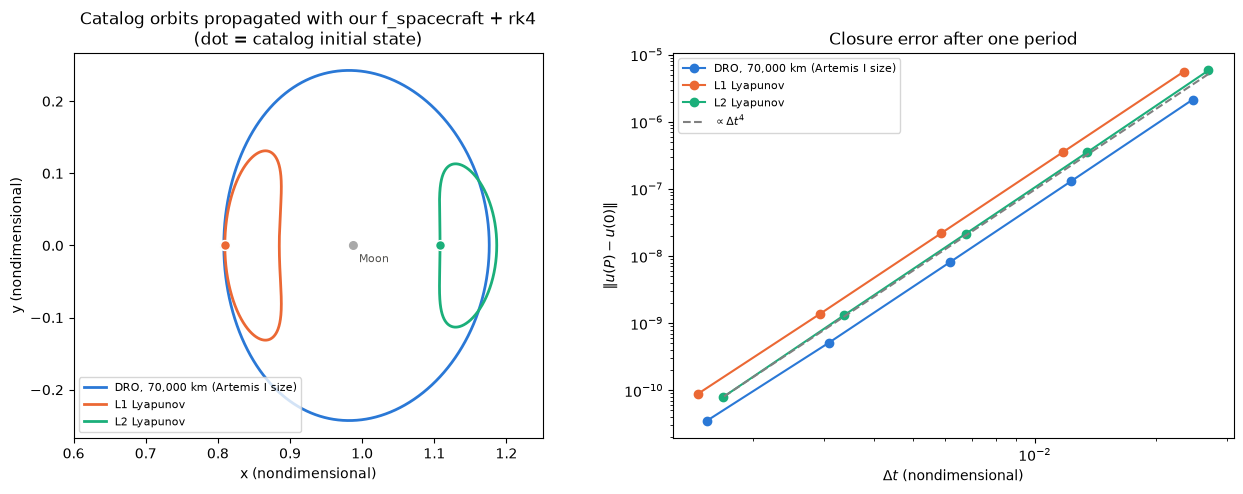

In [3]:
fig1 = plt.figure(figsize=(13, 5))
ax11 = fig1.add_subplot(121)
ax12 = fig1.add_subplot(122)

orbit_colours = ['#2a78d6', '#eb6834', '#1baf7a']

for orb, colour in zip(catalog, orbit_colours):
    ax11.plot(orb['u'][:, 0], orb['u'][:, 1], color=colour, lw=2, label=orb['name'])
    ax11.scatter(orb['u0'][0], orb['u0'][1], color=colour, edgecolors='WHITE', s=50, zorder=3)

    n_list = 2**np.arange(7, 12)
    errors = []
    for n in n_list:
        f = lambda u, t, mu=orb['mu']: f_spacecraft(u, t, mu)
        u, times = rk4(f, orb['u0'], orb['period'], orb['period']/n)
        errors.append(np.linalg.norm(u[-1] - orb['u0']))
    dt_list = orb['period']/n_list
    ax12.plot(dt_list, errors, 'o-', color=colour, label=orb['name'])

ax12.plot(dt_list, errors[-1]*(dt_list/dt_list[-1])**4, ls='--', color='GREY', label=r'$\propto \Delta t^4$')

mu_cat = catalog[0]['mu']
ax11.scatter([-mu_cat, 1 - mu_cat], [0, 0], color=['#2a78d6', 'DARKGREY'], s=[80, 30], zorder=4)
ax11.annotate('Moon', (1 - mu_cat, 0), xytext=(4, -12), textcoords='offset points', fontsize=8, color=INK)
ax11.set_xlim(0.6, 1.25)
ax11.set_aspect('equal')
ax11.set_title('Catalog orbits propagated with our f_spacecraft + rk4\n(dot = catalog initial state)')
ax11.set_xlabel('x (nondimensional)')
ax11.set_ylabel('y (nondimensional)')
ax11.legend(fontsize=8, loc='lower left')

ax12.set_xscale('log')
ax12.set_yscale('log')
ax12.xaxis.set_minor_formatter(plt.NullFormatter())
ax12.set_title('Closure error after one period')
ax12.set_xlabel(r'$\Delta t$ (nondimensional)')
ax12.set_ylabel(r'$\| u(P) - u(0) \|$')
ax12.legend(fontsize=8)

fig1.tight_layout()

**Result.** For all three orbits our Jacobi constant matches JPL's to about 14 significant figures. After one period, `rk4` returns to the catalogued starting point to within millimetres. The closure error follows the $\Delta t^4$ line until it reaches the round-off floor set by the 16-digit catalog values. That includes the two Lyapunov orbits, where an error in the Coriolis or gravity terms would be amplified several hundred times per period. These checks match JPL's independent computation, so the equations of motion and the integrator are correct.

For scale: the catalogued DRO of Artemis I's size has a period of about 14 days.

## Part 2: Artemis II

### The flown trajectory

Horizons serves Orion's flown trajectory from just after ICPS separation until entry. TLI was a 388 m/s burn by Orion's own engine from a 2,223 × 70,377 km high Earth orbit. This notebook starts the comparison **after TLI** (2026-04-03 00:30 TDB, about 35 minutes after the burn), so the model and the real flight start from the same state. All times are hours after the end of TLI.

The only burns after TLI were small trims (OTC-1 and OTC-2 were cancelled), plus one crew-module burn 17 minutes before entry:

In [4]:
for name, t, dv, kind in artemis2_burns:
    print(f'{name:<10}{t:7.1f} h after TLI  {dv:5.2f} m/s  {kind}')

jd, r_orion, v_orion = horizons_vectors(HORIZONS_ID, HORIZONS_START, HORIZONS_STOP, HORIZONS_STEP)
_, r_moon, v_moon = horizons_vectors(301, HORIZONS_START, HORIZONS_STOP, HORIZONS_STEP)

t_real = T_DATA_START + (jd - jd[0])*24 # h after TLI
d_earth_real = np.linalg.norm(r_orion, axis=1)
d_moon_real = np.linalg.norm(r_orion - r_moon, axis=1)
print(f'\n{len(jd)} Horizons samples from {t_real[0]:.2f} h to {t_real[-1]:.2f} h after TLI')

OTC-3        75.2 h after TLI   3.00 m/s  trim
RTC-1       120.2 h after TLI   0.49 m/s  trim
RTC-2       171.0 h after TLI   1.62 m/s  trim
RTC-3       187.0 h after TLI   1.28 m/s  trim
CM raise    191.7 h after TLI   3.00 m/s  entry

2297 Horizons samples from 0.58 h to 191.91 h after TLI


Horizons stops about 3 minutes before entry interface (EI), at 760 km altitude. To get the real entry speed and flight-path angle, the last Horizons state is carried forward to $r_{EI}$ = 6,499.9 km using two-body Earth gravity and our `rk4`. The Moon's pull over those 3 minutes is negligible. The cell below also checks the processed data against NASA's event list.

In [5]:
GM_EARTH = 398600.435 # km^3/s^2

f_two_body = lambda u, t: np.concatenate([u[3:], -GM_EARTH*u[:3]/np.linalg.norm(u[:3])**3])

u_tail, t_tail = rk4(f_two_body, np.concatenate([r_orion[-1], v_orion[-1]]), 600, 0.5)
r_tail = np.linalg.norm(u_tail[:, :3], axis=1)
j = np.where(r_tail <= R_EI)[0][0]
s = (r_tail[j - 1] - R_EI) / (r_tail[j - 1] - r_tail[j])
u_ei_real = u_tail[j - 1] + s*(u_tail[j] - u_tail[j - 1])

k_real = np.argmin(d_moon_real)
real = {
    'closest_approach': d_moon_real[k_real],
    't_closest_approach': t_real[k_real],
    'max_earth_dist': d_earth_real.max(),
    't_max_earth_dist': t_real[np.argmax(d_earth_real)],
    't_ei': t_real[-1] + (t_tail[j - 1] + s*0.5)/3600,
    'ei_speed': np.linalg.norm(u_ei_real[3:]),
    'ei_fpa': np.degrees(np.arcsin(u_ei_real[:3] @ u_ei_real[3:] / (np.linalg.norm(u_ei_real[:3])*np.linalg.norm(u_ei_real[3:])))),
}

print(f'{"":<34}{"From Horizons data":>20}{"NASA event list":>18}')
print(f'{"Closest approach, Moon centre (km)":<34}{real["closest_approach"]:>20.0f}{artemis2["closest_approach_moon_centre"]:>18.0f}')
print(f'{"   at (h after TLI)":<34}{real["t_closest_approach"]:>20.2f}{artemis2["t_closest_approach"]:>18.2f}')
print(f'{"Max distance from Earth (km)":<34}{real["max_earth_dist"]:>20.0f}{artemis2["max_earth_dist"]:>18.0f}')
print(f'{"   at (h after TLI)":<34}{real["t_max_earth_dist"]:>20.2f}{artemis2["t_max_earth_dist"]:>18.2f}')
print(f'{"Entry interface (h after TLI)":<34}{real["t_ei"]:>20.2f}{artemis2["t_ei"]:>18.2f}')
print(f'{"Entry speed (km/s)":<34}{real["ei_speed"]:>20.3f}{"-":>18}')
print(f'{"Entry flight-path angle (deg)":<34}{real["ei_fpa"]:>20.2f}{"-":>18}')
print(f'\nReal entry angle is inside the main.tex corridor [-7.4, -5.25] deg: {-7.4 <= real["ei_fpa"] <= -5.25}')

                                    From Horizons data   NASA event list
Closest approach, Moon centre (km)                8283              8282
   at (h after TLI)                              95.08             95.12
Max distance from Earth (km)                    413145            413146
   at (h after TLI)                              95.16             95.18
Entry interface (h after TLI)                   191.99            191.98
Entry speed (km/s)                              10.998                 -
Entry flight-path angle (deg)                    -5.99                 -

Real entry angle is inside the main.tex corridor [-7.4, -5.25] deg: True


### Putting the real trajectory in the model's frame

The model lives in the plane of the Moon's orbit, rotating with the Earth–Moon line. Each Horizons state is rotated into that frame using the Moon's position and velocity at the same instant (`freereturn.trajectory.rotating_frame`): $x$ toward the Moon, $z$ along the Moon's orbital angular momentum. Whatever lands in $z$ is what the planar model cannot represent.

In [6]:
r_rot_real = np.array([rotating_frame(rm, vm) @ r for r, rm, vm in zip(r_orion, r_moon, v_moon)])

def plane_tilt(i):
    h_orion = np.cross(r_orion[i], v_orion[i])
    h_moon = np.cross(r_moon[i], v_moon[i])
    return np.degrees(np.arccos(abs(h_orion @ h_moon) / (np.linalg.norm(h_orion)*np.linalg.norm(h_moon))))

i_return = np.argmin(np.abs(t_real - 150))
print(f'Tilt of Orion\'s orbit plane from the Moon\'s orbit plane: outbound {plane_tilt(0):.1f} deg, return leg {plane_tilt(i_return):.1f} deg')
print(f'Largest out-of-plane distance |z|: outbound {np.abs(r_rot_real[t_real < t_real[k_real], 2]).max():.0f} km, '
      f'return leg {np.abs(r_rot_real[t_real > t_real[k_real], 2]).max():.0f} km')
print(f'Out-of-plane distance at closest approach: {r_rot_real[k_real, 2]:.0f} km (vs {real["closest_approach"]:.0f} km pass distance)')
print(f'Earth-Moon distance over the flight: {np.linalg.norm(r_moon, axis=1).min():.0f} to {np.linalg.norm(r_moon, axis=1).max():.0f} km (model uses L = {L} km)')

Tilt of Orion's orbit plane from the Moon's orbit plane: outbound 0.9 deg, return leg 19.7 deg
Largest out-of-plane distance |z|: outbound 1227 km, return leg 13280 km
Out-of-plane distance at closest approach: 601 km (vs 8283 km pass distance)
Earth-Moon distance over the flight: 396657 to 404970 km (model uses L = 384400 km)


**Outbound**, Artemis II flew within about 1° of the Moon's orbital plane, so the planar model fits that leg well. Apollo 8's parking orbit, by contrast, was inclined 32.5°. **The lunar flyby changed that.** Passing a few hundred km off the plane bent the return leg about **19° out of the Moon's plane**, and on the way home Orion was up to about 13,000 km out of plane. This is the first clear limit of the planar model. It matters most for the entry angle, because the return perigee depends on the full 3-D geometry. That is tested at the end of this notebook.

The other big mismatch is the Moon's distance: in April 2026 the Moon was near apogee, about **405,000 km** away at the flyby, while the model fixes it at $L$ = 384,400 km.

**Getting a 3-D state into a planar model.** There are two reasonable ways (`state_from_inertial`):

- **Project:** drop the out-of-plane components. Simple, but on a tilted trajectory it changes the distance from Earth, the speed and the perigee.
- **Rotate:** tilt the spacecraft's own orbit plane into the Moon's plane about the line where the two planes cross. This keeps distance from Earth, speed and flight-path angle, so the Earth-relative orbit is unchanged.

The two are almost identical on the 1°-tilted outbound leg. The runs below use **rotate**.

### Three ways to run the model

Every run starts from Orion's **real post-TLI state**, rotated into the model's plane:

1. **Model as built** ($L$ = 384,400 km). The project's model exactly as it is.
2. **Moon at its real distance.** The same nondimensional equations, but with the length unit set to the Earth–Moon distance at the flyby and the time unit rescaled by Kepler's third law ($T \propto L^{3/2}$, `unit_scales`). This removes the biggest known mismatch without changing the model.
3. **Targeted.** As with Apollo 8's $\phi$, one free number is tuned to one real value: a small along-track velocity change $\delta v$ at the start, chosen by bisection so the model's closest approach matches the real 8,283 km. Everything else is then a prediction. The size of $\delta v$ is a useful number in its own right: it measures the model's simplifications as an equivalent TLI error.

In [7]:
L_FLYBY = np.linalg.norm(r_moon[k_real])
T_END_H = 215 # h after TLI, past entry interface

def run_model(lu, dv=0.0, n=2**15, i_start=0, method='rotate'):
    tu, vu = unit_scales(lu)
    u0 = state_from_inertial(r_orion[i_start], v_orion[i_start], r_moon[i_start], v_moon[i_start], lu, vu, method)

    # along-track delta-v [m/s] in the Earth-centred inertial frame
    v_in = np.array([u0[2] - u0[1], u0[3] + u0[0] + MU])
    u0[2:] += dv/1000/vu * v_in/np.linalg.norm(v_in)

    t_f = (T_END_H - t_real[i_start])*3600/tu
    u, times = rk4(f_spacecraft, u0, t_f, t_f/n)
    events = trajectory_events(u, times, lu, tu)

    t_h = t_real[i_start] + times*tu/3600
    events['t_perilune'] += t_real[i_start]
    events['t_ei'] += t_real[i_start]
    return {'u': u, 't': t_h, 'lu': lu, 'dv': dv, 'events': events}

def closest_approach(lu, dv, n=2**15):
    return moon_dist(run_model(lu, dv, n)['u'], lu).min()

def target_flyby(lu):
    # Coarse scan, then bisect the bracket nearest dv = 0 (the far-side pass, like the real flight)
    grid = np.arange(-25.0, 1.0, 1.0)
    passes = [closest_approach(lu, dv, 2**12) - real['closest_approach'] for dv in grid]
    i = max(i for i in range(len(grid) - 1) if passes[i]*passes[i + 1] < 0)

    lo, hi = grid[i], grid[i + 1]
    f_lo = closest_approach(lu, lo) - real['closest_approach']
    for _ in range(25):
        mid = 0.5*(lo + hi)
        f_mid = closest_approach(lu, mid) - real['closest_approach']
        if f_mid*f_lo > 0:
            lo, f_lo = mid, f_mid
        else:
            hi = mid
    return run_model(lu, 0.5*(lo + hi))

runs = {
    'As built, direct': run_model(L),
    'Real Moon distance, direct': run_model(L_FLYBY),
    'As built, targeted': target_flyby(L),
    'Real Moon distance, targeted': target_flyby(L_FLYBY),
}

for name, run in runs.items():
    ev = run['events']
    ending = (f'entry at {ev["t_ei"]:.1f} h, {ev["ei_fpa"]:+.1f} deg' if ev['entered']
              else f'no entry (return perigee {ev["return_perigee_alt"]:,.0f} km altitude)')
    print(f'{name:<30} dv = {run["dv"]:+6.2f} m/s   closest approach {moon_dist(run["u"], run["lu"]).min():8.0f} km   {ending}')

As built, direct               dv =  +0.00 m/s   closest approach    22341 km   no entry (return perigee 220,437 km altitude)
Real Moon distance, direct     dv =  +0.00 m/s   closest approach    17945 km   no entry (return perigee 184,046 km altitude)
As built, targeted             dv = -13.66 m/s   closest approach     8283 km   entry at 179.7 h, -40.0 deg
Real Moon distance, targeted   dv =  -7.99 m/s   closest approach     8283 km   entry at 192.2 h, -29.3 deg


Started directly from the real post-TLI state, the model **misses**: it passes the Moon at about 17,000–21,500 km instead of 8,283 km and never comes back to Earth. That is the sensitivity `main.tex` is built around. The lunar flyby amplifies small state errors, and the model's simplifications (no Sun, circular Moon orbit, planar projection) add up to the equivalent of a **few m/s** at TLI. With only that $\delta v$ applied, the model flies Artemis II's flyby and comes home. The size of $\delta v$ also falls as the model gets more realistic: it shrinks when the Moon is put at its real distance.

## Results: how good is the model?

Graded the same way as the Apollo 8 comparison. Only the closest-approach distance was targeted; everything below it is a prediction. The primary row set uses the **targeted model with the Moon at its real distance**; the as-built model's numbers are shown alongside.

In [8]:
def predictions(run):
    ev = run['events']
    lu = run['lu']
    i_ei = ev['ei_idx']
    d_e = earth_dist(run['u'][:i_ei], lu)
    k = np.argmax(d_e)
    return {
        'Time of closest approach': (run['t'][ev['perilune_idx']], real['t_closest_approach'], 'h'),
        'Max distance from Earth': (d_e[k], real['max_earth_dist'], 'km'),
        'Time of max distance': (run['t'][k], real['t_max_earth_dist'], 'h'),
        'Time of entry interface': (ev['t_ei'], real['t_ei'], 'h'),
        'Entry speed': (ev['ei_speed'], real['ei_speed'], 'km/s'),
        'Entry flight-path angle': (ev['ei_fpa'], real['ei_fpa'], 'deg'),
    }

primary = predictions(runs['Real Moon distance, targeted'])
as_built = predictions(runs['As built, targeted'])

print(f'Targeting delta-v: {runs["Real Moon distance, targeted"]["dv"]:+.2f} m/s (real Moon distance), '
      f'{runs["As built, targeted"]["dv"]:+.2f} m/s (as built)\n')
print(f'{"":<28}{"Artemis II":>12}{"Model":>12}{"Error":>9}  {"Grade":<13}{"As built":>12}{"Error":>9}  {"Grade":<12}')
print('-'*110)
for name, (model, real_value, unit) in primary.items():
    model_ab = as_built[name][0]
    pct, pct_ab = 100*(model - real_value)/abs(real_value), 100*(model_ab - real_value)/abs(real_value)
    print(f'{name + " (" + unit + ")":<28}{real_value:>12.2f}{model:>12.2f}{pct:>8.1f}%  {grade(pct):<13}{model_ab:>12.2f}{pct_ab:>8.1f}%  {grade(pct_ab):<12}')

Targeting delta-v: -7.99 m/s (real Moon distance), -13.66 m/s (as built)

                              Artemis II       Model    Error  Grade            As built    Error  Grade       
--------------------------------------------------------------------------------------------------------------
Time of closest approach (h)       95.08       94.33    -0.8%  Close match         86.62    -8.9%  Reasonable  
Max distance from Earth (km)   413144.81   413175.18     0.0%  Close match     392723.16    -4.9%  Close match 
Time of max distance (h)           95.16       94.51    -0.7%  Close match         86.98    -8.6%  Reasonable  
Time of entry interface (h)       191.99      192.19     0.1%  Close match        179.72    -6.4%  Reasonable  
Entry speed (km/s)                 11.00       10.98    -0.2%  Close match         10.97    -0.2%  Close match 
Entry flight-path angle (deg)       -5.99      -29.27  -388.8%  Off                -39.98  -567.6%  Off         


6 predicted quantities: 5 close match, 0 reasonable, 1 off


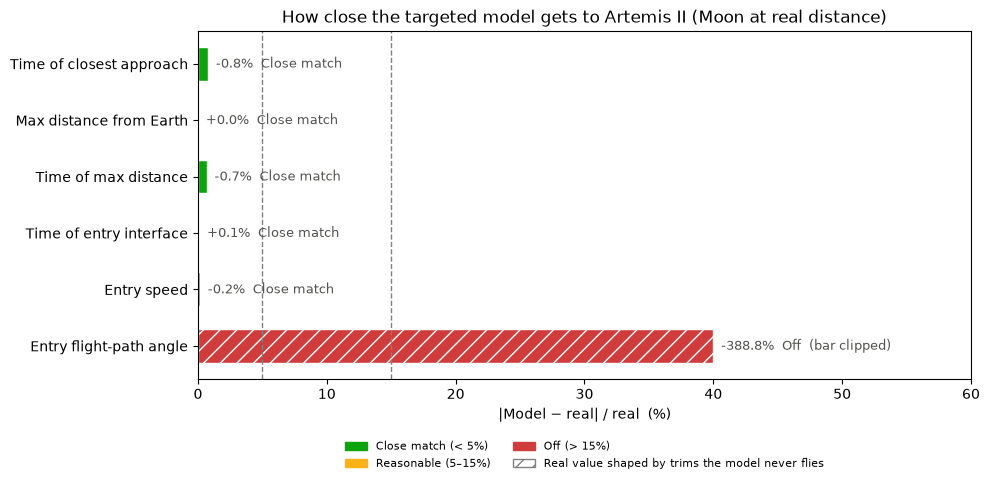

In [9]:
names = list(primary)
pct_errors = [100*(m - r)/abs(r) for m, r, unit in primary.values()]
# The real entry angle includes 4.4 m/s of return trims and the CM raise burn the model never flies
loose = [name.startswith('Entry flight-path') for name in names]

fig2 = plt.figure(figsize=(10, 5))
ax21 = fig2.add_subplot(111)
plot_scorecard(ax21, names, pct_errors, loose,
               'How close the targeted model gets to Artemis II (Moon at real distance)',
               'Real value shaped by trims the model never flies')
fig2.tight_layout()

counts = {g: sum(grade(p) == g for p in pct_errors) for g in ('Close match', 'Reasonable', 'Off')}
print(f'{len(names)} predicted quantities: ' + ', '.join(f'{n} {g.lower()}' for g, n in counts.items()))

## Trajectory vs time, with Artemis II's burns

Dotted lines are the trims. The dashed **CM raise** line is the one burn that deliberately changes the trajectory the model would fly: after the service module separates, the crew module fires to set its final entry angle.

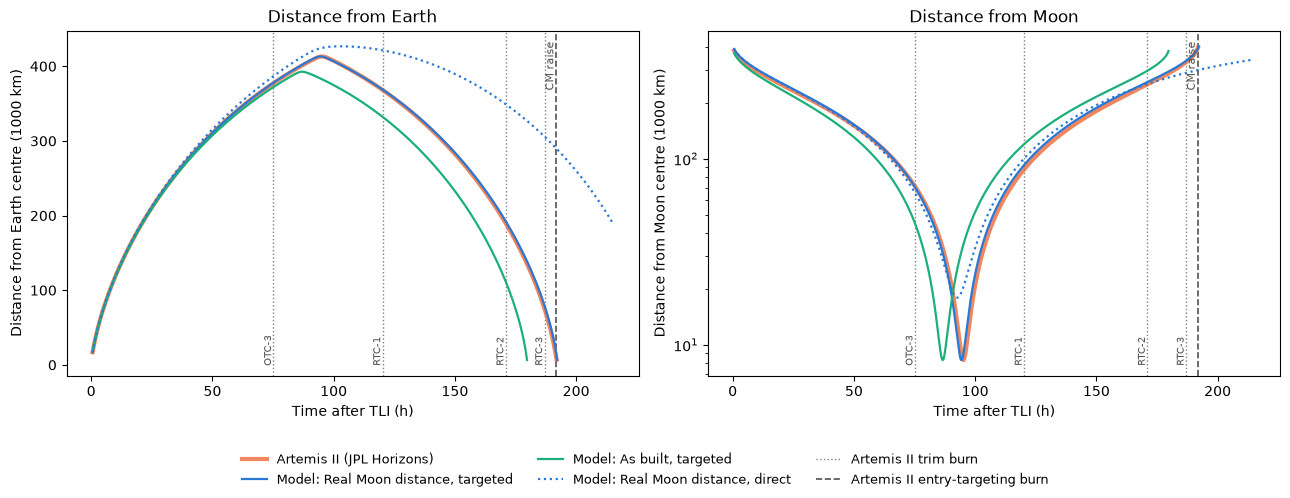

In [10]:
def mark_burns(ax):
    for name, t, dv, kind in artemis2_burns:
        if kind == 'trim':
            ax.axvline(t, color='GREY', ls=':', lw=1)
            ax.text(t, 0.02, f' {name} ', transform=ax.get_xaxis_transform(), rotation=90, va='bottom', ha='right', fontsize=7, color=INK)
        else:
            ax.axvline(t, color=INK, ls='--', lw=1.2)
            ax.text(t, 0.98, f' {name} ', transform=ax.get_xaxis_transform(), rotation=90, va='top', ha='right', fontsize=8, color=INK)

plotted = [('Real Moon distance, targeted', MODEL_COLOUR, '-'), ('As built, targeted', MODEL_L_COLOUR, '-'),
           ('Real Moon distance, direct', MODEL_COLOUR, ':')]

fig3 = plt.figure(figsize=(13, 5))
ax31 = fig3.add_subplot(121)
ax32 = fig3.add_subplot(122)

for ax, dist_fn, d_real in ((ax31, earth_dist, d_earth_real), (ax32, moon_dist, d_moon_real)):
    mark_burns(ax)
    ax.plot(t_real, d_real/1000, color=REAL_COLOUR, lw=3, alpha=0.8, label='Artemis II (JPL Horizons)')
    for name, colour, ls in plotted:
        run = runs[name]
        n_end = run['events']['ei_idx'] + 2 if run['events']['entered'] else len(run['t'])
        ax.plot(run['t'][:n_end], dist_fn(run['u'][:n_end], run['lu'])/1000, color=colour, ls=ls, lw=1.6, label=f'Model: {name}')
    ax.set_xlabel('Time after TLI (h)')

ax31.set_title('Distance from Earth')
ax31.set_ylabel('Distance from Earth centre (1000 km)')
ax32.set_title('Distance from Moon')
ax32.set_ylabel('Distance from Moon centre (1000 km)')
ax32.set_yscale('log')

handles, labels = ax32.get_legend_handles_labels()
handles += [plt.Line2D([], [], color='GREY', ls=':', lw=1), plt.Line2D([], [], color=INK, ls='--', lw=1.2)]
labels += ['Artemis II trim burn', 'Artemis II entry-targeting burn']
fig3.legend(handles, labels, loc='lower center', ncol=3, fontsize=9, frameon=False)
fig3.tight_layout(rect=(0, 0.12, 1, 1))

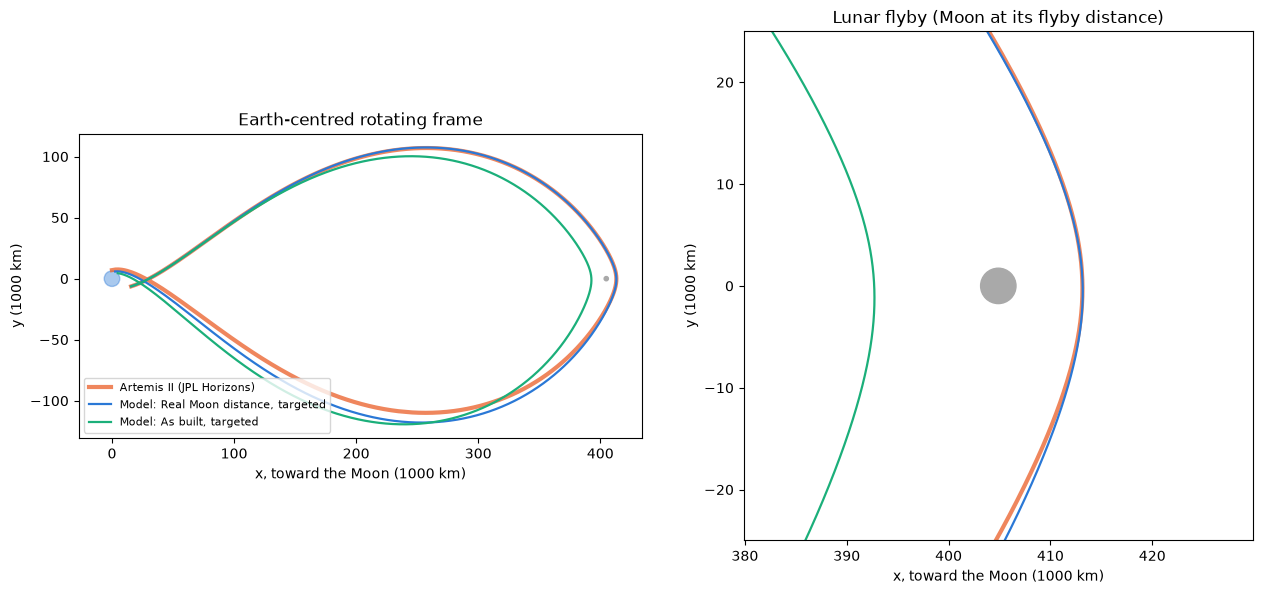

In [11]:
fig4 = plt.figure(figsize=(13, 6))
ax41 = fig4.add_subplot(121)
ax42 = fig4.add_subplot(122)

for ax in (ax41, ax42):
    ax.plot(r_rot_real[:, 0]/1000, r_rot_real[:, 1]/1000, color=REAL_COLOUR, lw=3, alpha=0.8, label='Artemis II (JPL Horizons)')
    for name, colour, ls in plotted[:2]:
        run = runs[name]
        n_end = run['events']['ei_idx'] + 2
        u = run['u'][:n_end]
        ax.plot((u[:, 0] + MU)*run['lu']/1000, u[:, 1]*run['lu']/1000, color=colour, ls=ls, lw=1.6, label=f'Model: {name}')
    ax.add_patch(plt.Circle((0, 0), R_EARTH/1000, color=MODEL_COLOUR, alpha=0.4))
    ax.add_patch(plt.Circle((L_FLYBY/1000, 0), R_MOON/1000, color='DARKGREY'))
    ax.set_aspect('equal')
    ax.set_xlabel('x, toward the Moon (1000 km)')
    ax.set_ylabel('y (1000 km)')

ax41.set_title('Earth-centred rotating frame')
ax41.legend(fontsize=8, loc='lower left')

ax42.set_title('Lunar flyby (Moon at its flyby distance)')
ax42.set_xlim(L_FLYBY/1000 - 25, L_FLYBY/1000 + 25)
ax42.set_ylim(-25, 25)

fig4.tight_layout()

## How far ahead can the model predict the entry angle?

Entry angle is the one quantity the targeted model gets badly wrong, and it is the quantity `main.tex` cares about most. To see why, restart the model (Moon at its real distance, no targeting) from Artemis II's **real** state at a series of times along the flight, and record the entry angle it predicts each time. This is the forecasting version of research question Q2: how much does it matter *when* you look?

Each restart is done both ways, **project** and **rotate**, to show how much of the miss comes from the 3-D return leg.

 restart (h)   project    rotate
           0  no entry  no entry
           8    -55.80    -55.93
          16    -50.91    -50.96
          24    -47.12    -47.15
          32    -43.55    -43.56
          40    -39.69    -39.68
          48    -36.07    -36.05
          56    -33.07    -33.03
          64    -29.51    -29.44
          72    -27.16    -27.05
          80    -25.35    -25.28
          88    -27.69    -26.58
          96    -30.86    -35.05
         104    -18.77  no entry
         112    -17.66  no entry
         120    -17.70  no entry
         128    -18.33  no entry
         136    -18.59  no entry
         144    -18.92  no entry
         152    -19.20  no entry
         160    -19.30  no entry
         168    -19.40     -1.74
         170    -19.43     -2.25
         172    -19.90     -5.46
         174    -19.92     -5.60
         176    -19.94     -5.70
         178    -19.95     -5.80
         180    -19.96     -5.89
         182    -19.97     -5.94
         1

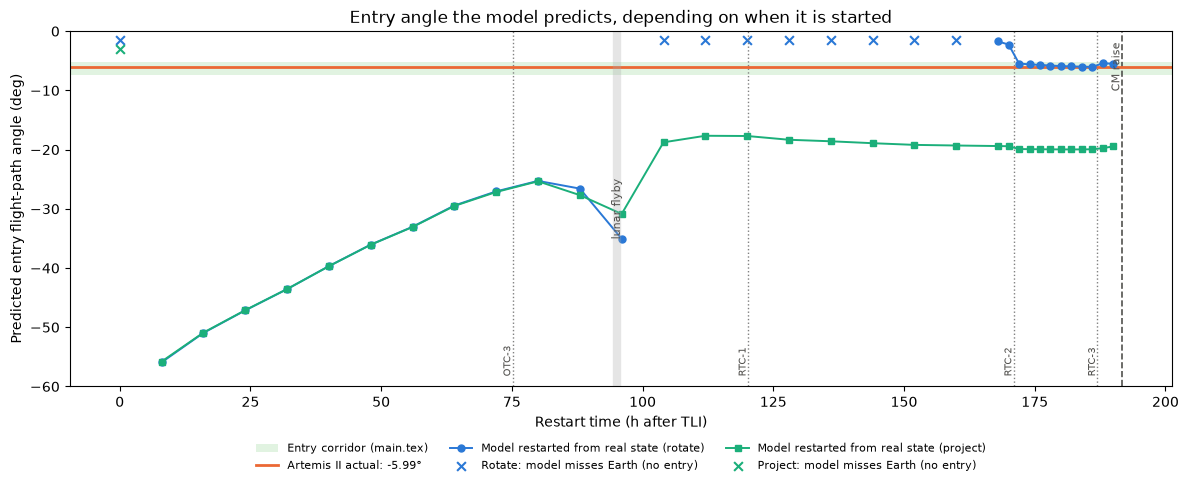

In [12]:
restart_hours = np.concatenate([np.arange(0, 168, 8.0), np.arange(168, 191, 2.0)])
restart_fpa = {'project': [], 'rotate': []}

for t_r in restart_hours:
    i_r = np.argmin(np.abs(t_real - t_r))
    lu_r = np.linalg.norm(r_moon[i_r])
    n = max(2**10, int(2**15*(T_END_H - t_real[i_r])/T_END_H))
    for method in restart_fpa:
        ev = run_model(lu_r, n=n, i_start=i_r, method=method)['events']
        restart_fpa[method].append(ev['ei_fpa'] if ev['entered'] else np.nan)

restart_fpa = {m: np.array(v) for m, v in restart_fpa.items()}

fig5 = plt.figure(figsize=(12, 5))
ax51 = fig5.add_subplot(111)
mark_burns(ax51)
ax51.axhspan(-7.4, -5.25, color='#0ca30c', alpha=0.12, lw=0, label='Entry corridor (main.tex)')
ax51.axhline(real['ei_fpa'], color=REAL_COLOUR, lw=2, label=f'Artemis II actual: {real["ei_fpa"]:.2f}°')

for method, colour, marker in (('rotate', MODEL_COLOUR, 'o'), ('project', MODEL_L_COLOUR, 's')):
    fpa = restart_fpa[method]
    ok = np.isfinite(fpa)
    # NaNs (no entry) break the line instead of joining across the gap
    ax51.plot(restart_hours, fpa, marker=marker, ls='-', color=colour, lw=1.4, ms=5, label=f'Model restarted from real state ({method})')
    ax51.scatter(restart_hours[~ok], np.full((~ok).sum(), -1.5 if method == 'rotate' else -3.0), marker='x', color=colour, s=40,
                 label=f'{method.capitalize()}: model misses Earth (no entry)')

ax51.axvline(real['t_closest_approach'], color='DARKGREY', lw=6, alpha=0.3)
ax51.text(real['t_closest_approach'], 0.5, ' lunar flyby ', transform=ax51.get_xaxis_transform(), rotation=90, va='center', ha='center', fontsize=8, color=INK)
ax51.set_ylim(-60, 0)
ax51.set_xlabel('Restart time (h after TLI)')
ax51.set_ylabel('Predicted entry flight-path angle (deg)')
ax51.set_title('Entry angle the model predicts, depending on when it is started')
ax51.legend(fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.13), ncol=3, frameon=False)
fig5.tight_layout()

print(f'{"restart (h)":>12}{"project":>10}{"rotate":>10}')
for t_r, fp, fr in zip(restart_hours, restart_fpa['project'], restart_fpa['rotate']):
    fmt = lambda x: f'{x:+10.2f}' if np.isfinite(x) else f'{"no entry":>10}'
    print(f'{t_r:>12.0f}{fmt(fp)}{fmt(fr)}')

**What the restart plot shows**

- **Before the flyby**, both ways of starting the model predict entry angles that are far too steep. They improve steadily as the start moves closer to the Moon. The flyby amplifies any error in the incoming state, so the further from the flyby the model starts, the worse its forecast.
- **During the mid-return coast** (about 104–168 h), the "rotate" runs miss Earth entirely and the "project" runs settle near −19°. Neither is right. The return leg is tilted about 20° out of the Moon's plane, while the Moon is still close enough to steer it, and a planar model cannot represent that geometry.
- **In the last ~20 hours**, the Moon's pull no longer matters. The "rotate" run, which keeps the true Earth-relative orbit, predicts the real entry angle to within about 0.5° from 172 h onward. The "project" run stays stuck near −20°, because flattening a 20°-tilted orbit changes its perigee.
- **The burns show up as steps.** After RTC-3 (187 h), the forecast shifts to about −5.4°. The model never flies the final 3 m/s CM-raise burn, which is what moved the real entry to −5.99°.

## Verdict

**JPL catalog (code verification).** Our `f_spacecraft`, `jacobi_constant` and `rk4` reproduce JPL's independently computed periodic orbits. The Jacobi constant matches to about 14 digits, the orbits close to within millimetres, and the error converges at fourth order, including on two strongly unstable Lyapunov orbits. Any mismatch with Artemis II is therefore down to the *physics the model leaves out*, not to bugs.

**Artemis II (model accuracy).**

- **About 8 m/s separates the model from the real flight.** Started directly from the real post-TLI state, the model passes the Moon at about 18,000 km instead of 8,283 km and never returns. An along-track change of only −8.0 m/s makes it fly Artemis II's flyby. With $L$ = 384,400 km as built, it takes −13.7 m/s. Measured in TLI error, the model's simplifications are worth a few to about ten m/s.
- **Once the flyby is matched and the Moon is at its real distance, the big picture is a close match**, 5 of 6 predictions within 1%:
  - flyby time within about 45 minutes,
  - maximum distance from Earth within 30 km,
  - entry-interface time within about 12 minutes,
  - entry speed within 0.2%.

  With the as-built $L$, the timings drift by 6–9%, almost entirely because the Moon was ~5% farther away than $L$ in April 2026.
- **The entry angle is the miss, as `main.tex` predicts.** Forecast from TLI, it comes out at about −29° against the real −5.99°. Two things cause this:
  - The return perigee is the most sensitive quantity in the problem. Artemis II itself needed 3.4 m/s of return trims plus a 3 m/s crew-module burn to sit in the corridor.
  - The flyby tilted the return leg about 20° out of the Moon's plane, which a planar model cannot follow.

  Started within the last ~20 hours, with the 3-D state rotated into the plane, the model gets the entry angle right to within about 0.5°.

**Compared with Apollo 8**, Artemis II is a cleaner test: a true free return with a fully published trajectory and no lunar-orbit phase. The model does at least as well on everything except the entry angle. For both missions the entry angle is controlled by small effects that only midcourse corrections can fix, which is the motivation for Q2 in `main.tex`.

**What this means for `main.tex`.** The *Scope and limitations* section already says absolute values will differ from a real mission. Artemis II puts numbers on that:
- **Neglected forces:** together the model's omissions are worth about 8–14 m/s at TLI.
- **Planar assumption:** the biggest effect on $\gamma_{EI}$ comes from the planar assumption on the return leg after an out-of-plane flyby, more than from solar gravity or $J_2$.
- **Where the planar model holds:** it supports the study's *trends and orders of magnitude*, and its absolute $\gamma_{EI}$ predictions are only trustworthy close to Earth.